# Principal Component Analysis (PCA) on Fruit Images

PCA is an **unsupervised dimensionality reduction** technique. In this notebook I apply it to 300 grayscale fruit images (apples, pineapples, bananas; 100×100 px, i.e. 10,000 features each) and look at:

1. What the principal components look like
2. How much information is lost when 10,000 features are reduced to 50
3. Whether PCA speeds up a classifier without hurting accuracy
4. How PCA and K-Means work together

**Libraries:** NumPy, scikit-learn, Matplotlib

---
## 1. Background

### What is PCA?
PCA transforms a dataset with many features into a dataset with fewer features while keeping as much of the original information (variance) as possible.

### Core concepts
- **Dimensionality reduction:** High-dimensional data is hard to visualize and expensive to compute on. PCA projects it onto fewer dimensions.
- **Variance:** Variance is the spread of the data, which PCA treats as information. PCA looks for the directions (axes) along which the data is most spread out.
- **Principal components (PCs):** The new, uncorrelated axes, built as linear combinations of the original features.
  - **PC1** is the direction with the largest variance.
  - **PC2** is the direction perpendicular (orthogonal) to PC1 with the next largest variance, and so on.

### Why use PCA?
- **Visualization:** Data with 4 or more dimensions can be reduced to 2D or 3D and plotted.
- **Speed:** Fewer, less redundant features mean cheaper training.
- **Noise reduction:** Low-variance components often capture mostly noise, and PCA can drop them.

---
## 2. Load the Data
Download the fruit dataset and flatten each image into a 10,000-length vector, because scikit-learn expects a 2D array of shape `(samples, features)`.

In [ ]:
# Load the fruit dataset and flatten each 100x100 image into a 10,000-length vector.
import numpy as np
!wget https://bit.ly/fruits_300_data -O fruits_300.npy
fruits = np.load('fruits_300.npy')
fruits_2d = fruits.reshape(-1, 100*100)

--2026-11-14 21:40:56--  https://bit.ly/fruits_300_data
Resolving bit.ly (bit.ly)... 67.199.248.10, 67.199.248.11
Connecting to bit.ly (bit.ly)|67.199.248.10|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://github.com/rickiepark/hg-mldl/raw/master/fruits_300.npy [following]
--2026-11-14 21:40:56--  https://github.com/rickiepark/hg-mldl/raw/master/fruits_300.npy
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fruits_300.npy [following]
--2026-11-14 21:40:56--  https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fruits_300.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... conne

---
## 3. Fit PCA with 50 Components
`n_components=50` asks PCA to keep the 50 directions that explain the most variance. Like K-Means, PCA is unsupervised, so `fit()` receives only the input data and no labels.

In [ ]:
# Fit PCA with 50 components on the flattened images.
from sklearn.decomposition import PCA
pca = PCA(n_components=50)
pca.fit(fruits_2d)

PCA(n_components=50)

`components_` has shape `(50, 10000)`: 50 components, each with one weight per pixel. Because each component has the same length as an image, it can be reshaped back to 100×100 and drawn.

In [ ]:
# Each row of components_ is one principal component (a 10,000-length vector).
print(pca.components_.shape)

(50, 10000)


### Principal components as images
Each image below is one principal component. These are the pixel patterns that capture the most variation across the dataset, and the earliest components explain the most.

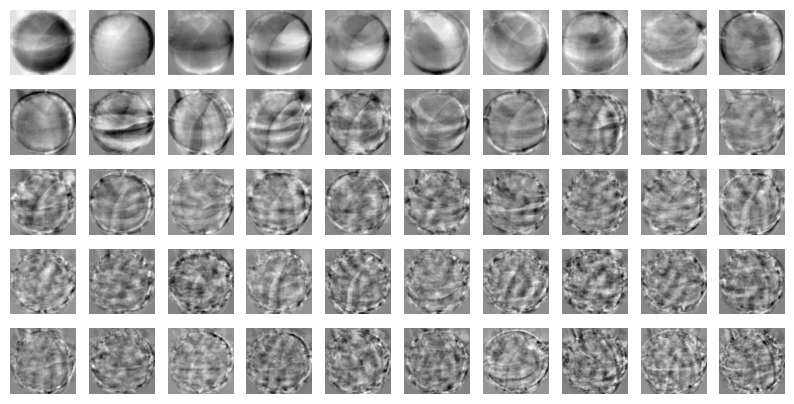

In [ ]:
# Helper function: draw images in a grid, 10 images per row.
import matplotlib.pyplot as plt
def draw_fruits(arr, ratio = 1):
  n = len(arr)  # number of images
  rows = int(np.ceil(n/10))  # 10 images per row
  cols = n if rows < 2 else 10
  fig, axs = plt.subplots(rows, cols, figsize = (cols*ratio, rows*ratio), squeeze=False)
  for i in range(rows):
    for j in range(cols):
      if i*10 + j < n:
        axs[i,j].imshow(arr[i*10+j], cmap='gray_r')
      axs[i,j].axis('off')
  plt.show()

# Reshape the 50 components back to 100x100 images and draw them.
draw_fruits(pca.components_.reshape(-1,100,100))

---
## 4. Reduce the Dimensions
`transform()` projects every image onto the 50 components, shrinking each sample from 10,000 features to 50, which is **1/200 of the original size**.

In [ ]:
# Reduce the dataset from 10,000 features to 50 with transform().
fruits_pca = pca.transform(fruits_2d)
print(f"Before transformation: {fruits_2d.shape}")
print(f"After transformation: {fruits_pca.shape}")

Before transformation: (300, 10000)
After transformation: (300, 50)


---
## 5. Reconstruct the Original Images
Even after shrinking the data 200 times, it can be mapped back to the original size with `inverse_transform()`.

In [ ]:
# Restore the reduced data to (300, 10000) with inverse_transform().
fruits_inverse = pca.inverse_transform(fruits_pca)
print(fruits_inverse.shape)

(300, 10000)


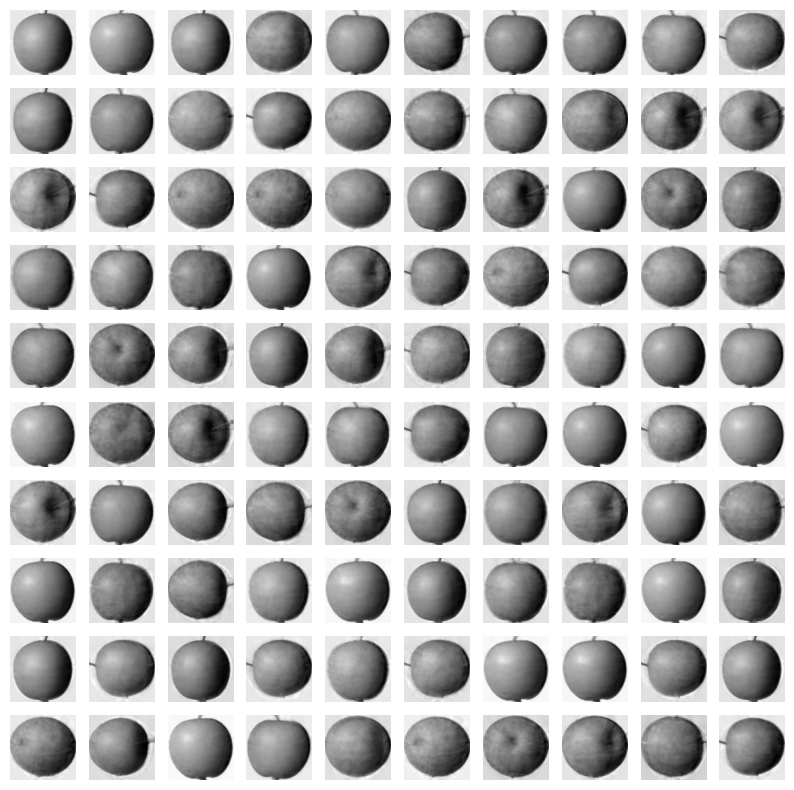

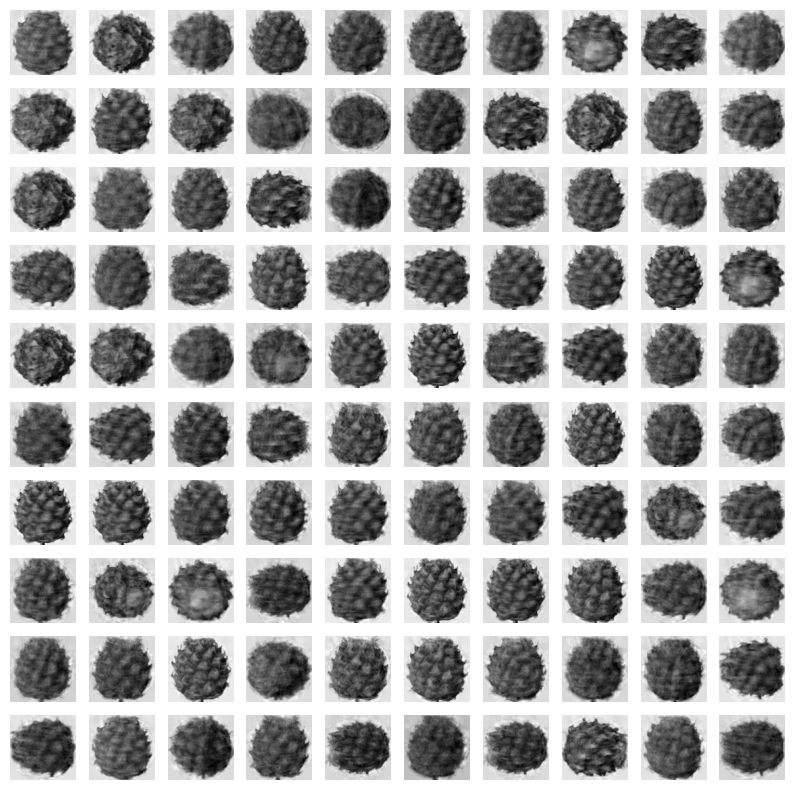

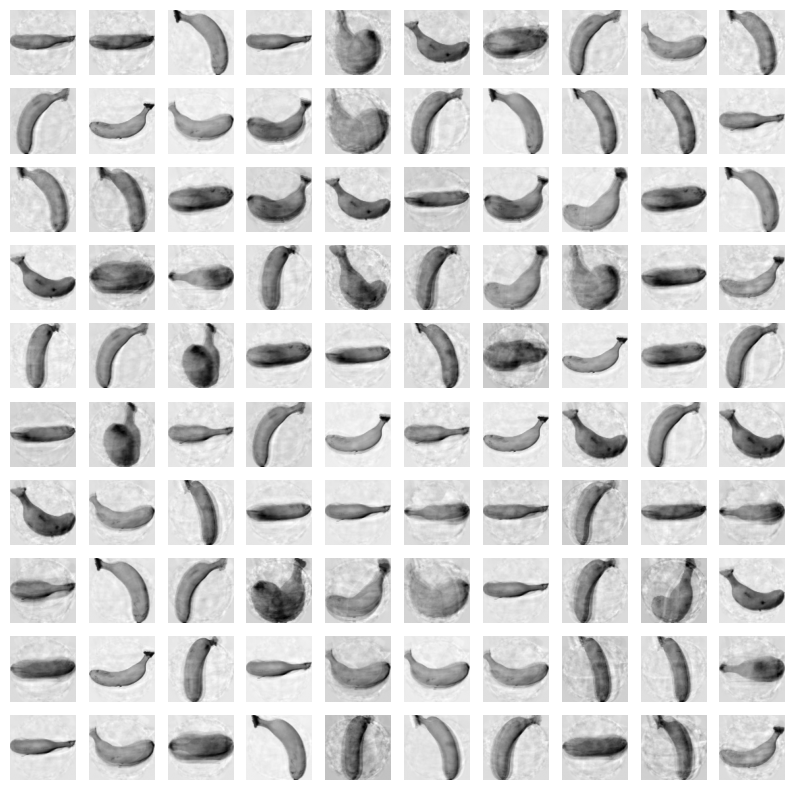

In [ ]:
# Reshape the restored data into 100x100 images and draw them, 100 at a time.
fruits_reconstruct = fruits_inverse.reshape(-1,100,100)
for start in [0, 100, 200]:
  draw_fruits(fruits_reconstruct[start:start+100])
  print("\n")

The reconstructed images are close to the originals, but some are blurry. The reduction from 10,000 to 50 features **permanently discards some information**, so the reconstruction is an approximation.

---
## 6. How Much Information Is Kept?
The question is how much of the original information 50 components retain. This is measured by the **explained variance ratio**, which `pca.explained_variance_ratio_` reports for each component. Summing it gives the total fraction of variance explained.

In [ ]:
# Total explained variance ratio of the 50 components.
print(np.sum(pca.explained_variance_ratio_))

0.9214264268823457


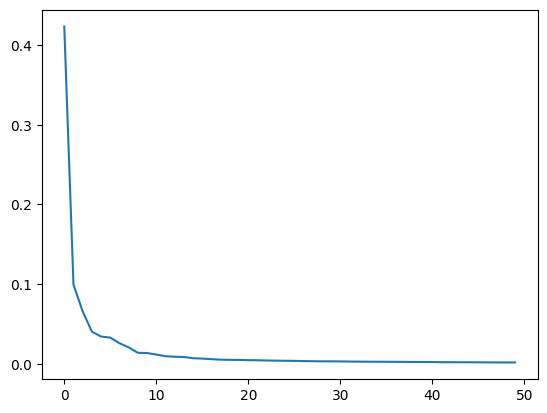

In [ ]:
# Plot the explained variance ratio of each component.
plt.plot(pca.explained_variance_ratio_)
plt.show()

The 50 components explain about **92% of the variance**, so roughly 8% of the information is lost. The plot also shows that the first few components explain most of the variance and later ones add very little. So far fewer than 50 components could preserve almost the same information.

Plotting this curve is a common way to decide how many components to keep.

---
## 7. Does PCA Help a Classifier?
PCA should make training faster and may remove noise. To test this, I train a Logistic Regression model on both the original data and the PCA-reduced data, using **the same 5-fold stratified splits** so the comparison is fair. The target is built by hand: 0 = apple, 1 = pineapple, 2 = banana.

In [ ]:
# Load Logistic Regression and the cross-validation tools.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
import numpy as np

# Fix the model with random_state.
lr = LogisticRegression(random_state=42)

# Fix the cross-validation splits with StratifiedKFold and random_state.
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create the target array. 0 = Apple, 1 = Pineapple, 2 = Banana
target = np.array([0]*100 + [1]*100 + [2]*100)

# Cross-validate on the original data and on the PCA-reduced data with the same splits.
scores = cross_validate(lr, fruits_2d, target, cv=splitter)
scores_pca = cross_validate(lr, fruits_pca, target, cv=splitter)

# Test score
print(f"Test score for (300,10000): {round(np.mean(scores['test_score']),4)}")
print(f"Test score for (300,50): {round(np.mean(scores_pca['test_score']),4)}")
print("\n")
# Fit time
print(f"Fit time for (300,10000): {np.mean(scores['fit_time']):.4f}s")
print(f"Fit time for (300,50): {np.mean(scores_pca['fit_time']):.4f}s")
print("\n")
# Comparison
print(f"Fit time ratio: {round(np.mean(scores['fit_time'])/np.mean(scores_pca['fit_time']),2)}x faster")

Test score for (300,10000): 0.9967
Test score for (300,50): 0.9967


Fit time for (300,10000): 0.8182s
Fit time for (300,50): 0.0223s


Fit time ratio: 36.73x faster


### Result
- **Preserved accuracy:** The cross-validation score is **0.9967** for both the original and the PCA-reduced data.
- **Much faster training:** Fit time drops from about 0.82 s to 0.02 s, roughly **37× faster** in this run. The exact ratio varies between runs because training takes only milliseconds, but the speedup is large.

Reducing 10,000 features to 50 made training much faster without hurting accuracy, though it did not improve it here, since the original data was already classified nearly perfectly.

---
## 8. Choose the Number of Components by Variance
Instead of choosing the number of components directly, `n_components` can be a **float between 0 and 1**. PCA then keeps the smallest number of components that explain at least that fraction of the variance.

With `n_components=0.5`, just **2 components** explain about 52% of the variance. That is few enough to plot in 2D.

In [ ]:
# Passing a float between 0 and 1 as n_components keeps just enough components
# to explain that fraction of the total variance.
# Here, 0.5 finds the minimum number of components that explain 50% of the variance.
pca = PCA(n_components=0.5)
pca.fit(fruits_2d)
fruits_pca = pca.transform(fruits_2d)

# Number of components kept
print(f"Number of components: {pca.n_components_}")
# Shape of the reduced dataset
print(f"Reduced dataset's shape: {fruits_pca.shape}")
# Explained variance ratio
print(f"Explained variance ratio: {np.sum(pca.explained_variance_ratio_)}")

2
(300, 2)
0.5229877245800598


---
## 9. PCA + K-Means
Next, I cluster the 2-component data with K-Means.

(array([0, 1, 2], dtype=int32), array([110,  99,  91]))


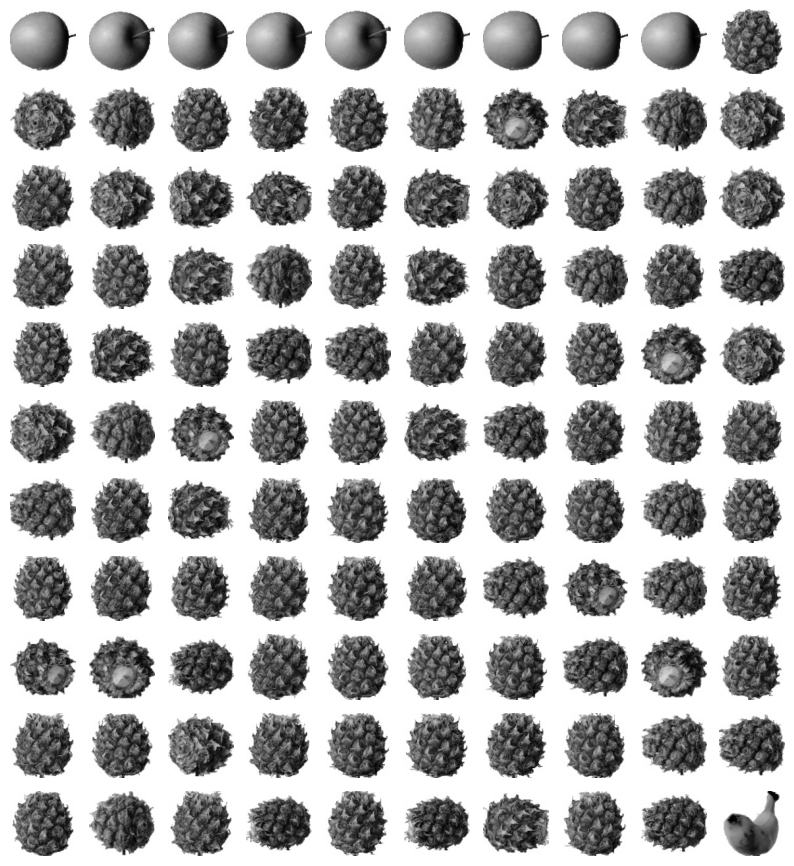

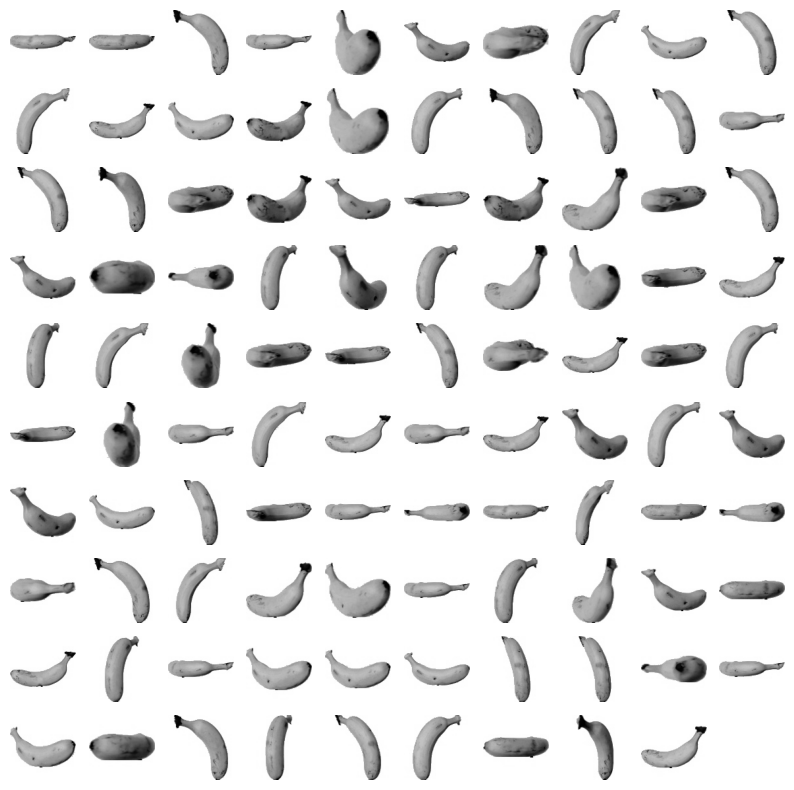

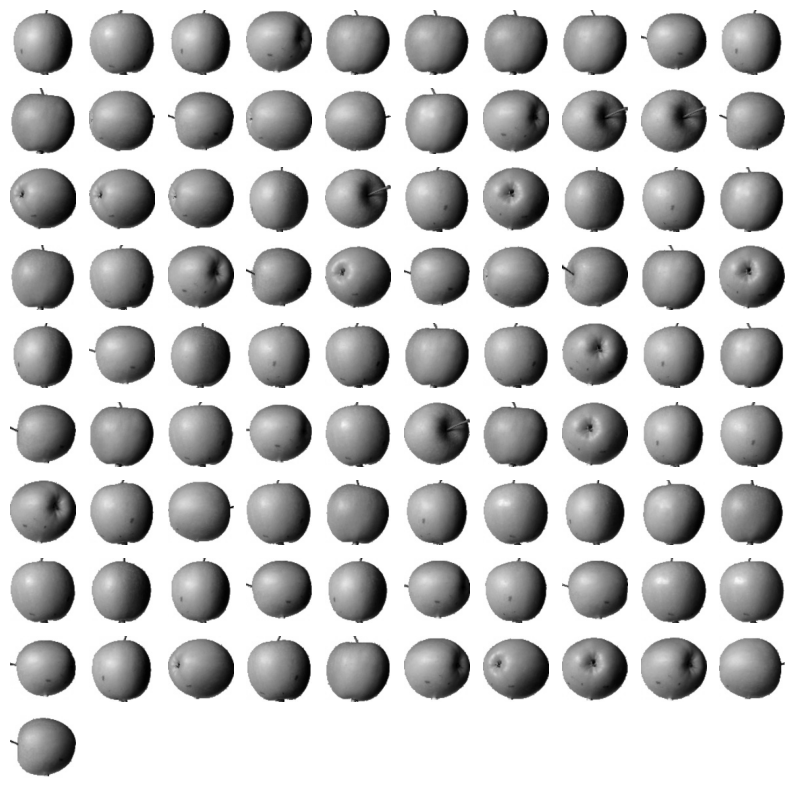

In [ ]:
# Cluster the reduced data with K-Means.
from sklearn.cluster import KMeans
km = KMeans(n_clusters=3, random_state=42)
km.fit(fruits_pca)
print(np.unique(km.labels_, return_counts=True))

for label in range(0,3):
  draw_fruits(fruits[km.labels_ == label])
  print("\n")

Cluster sizes are 110, 99 and 91, but each fruit has exactly 100 images, so some images were grouped with the wrong fruit. Checking against the known order of the data:

| Cluster | Size | Contents |
|---|---|---|
| 0 | 110 | 100 pineapples + 9 apples + 1 banana |
| 1 | 99 | 99 bananas |
| 2 | 91 | 91 apples |

K-Means separated bananas almost perfectly. It put 9 apples into the pineapple cluster. A scatterplot of the two components shows why.

---
## 10. Visualize the Clusters

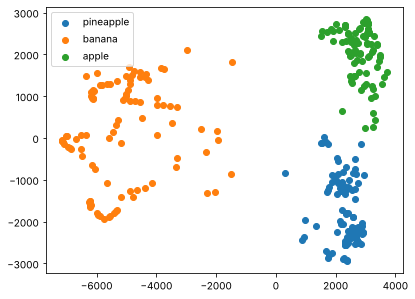

In [ ]:
# Scatterplot of the two components, colored by cluster.
# The legend names were assigned after checking which fruit each cluster contains.
for label in range(0,3):
  data = fruits_pca[km.labels_ == label]
  plt.scatter(data[:,0],data[:,1])
plt.legend(["pineapple","banana","apple"])
plt.show()

### Reading the plot
- **Banana** (orange) is far from the other two clusters, so it is easy to separate. This is why bananas were grouped almost perfectly.
- **Apple** and **pineapple** are much closer to each other. The few apples that sit near the pineapple cluster are the ones K-Means misclassified, because their nearest neighbors in the 2D space were pineapples.
- With only 2 components (about 52% of the variance), part of the information that separates apples from pineapples is lost. Using more components preserves more variance and should give clearer boundaries between the classes.

---
## Summary

| Step | Method | Result |
|---|---|---|
| Fit PCA | `PCA(n_components=50)` | 50 components, each a 10,000-length vector |
| Reduce | `transform()` | (300, 10000) → (300, 50) |
| Restore | `inverse_transform()` | Back to (300, 10000), with some blur |
| Information kept | `explained_variance_ratio_` | 50 components explain about 92% |
| Classifier test | Logistic Regression + 5-fold CV | Same score (0.9967), about 37× faster |
| Choose by variance | `PCA(n_components=0.5)` | 2 components explain about 52% |
| Clustering | K-Means on 2 components | Bananas separated well, some apples mixed with pineapples |

### Key takeaways
1. PCA keeps the directions of largest variance, so much of the information survives even a 200× reduction in features.
2. `explained_variance_ratio_` tells you how much information is retained and helps you choose the number of components.
3. A float `n_components` selects the number of components by the variance you want to keep.
4. The reduction is lossy, and `inverse_transform()` only recovers an approximation of the original data.
5. Reducing to 2 or 3 components makes high-dimensional data easy to visualize, at the cost of losing some detail.